In [8]:
%load_ext autoreload
%autoreload 2

import os, sys
import pandas as pd

module_path = os.path.abspath(os.path.join('../..'))
if module_path not in sys.path:
    sys.path.append(module_path)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
from langchain_core.messages import HumanMessage

In [10]:
from src.utils.knowledge import Knowledge
from src.workflows.support_agent import SupportAgent, SupportState, get_support_agent
from src.models.workflow import WorkflowSettings

In [11]:
from src.utils.injest import load_observation


df = load_observation('../../datasets/observations/Transactions.csv')
df.head()

,Id,Date,Amount,Entity,Entity_Id,Type,Category,Description,Mode,Related Party,Reference
0,1,5/26/2026,"₦680,000.00",Loan,NaN,Credit,Loan,Loan Investment,Transfer,Kennedy Ikeka,Credit_Loan_1
1,2,5/26/2026,"₦220,000.00",Pond,1,Debit,Utilities,Fish Pond Rent,Transfer,Kelechi,Debit_Utilities_1
2,3,5/29/2026,"₦19,000.00",Utility,1,Debit,Utilities,Fish Pond Net,Transfer,Rafiat Shonoiki,Debit_Utilities_2
3,4,5/31/2026,"₦11,000.00",Cycle,1,Debit,Inventory,Fish Stocking,Transfer,NaN,Debit_Inventory_1
4,5,6/1/2026,"₦13,036.00",Feed,1,Debit,Inventory,Fish Feed Stocking,Transfer,Lucky Eselojor,Debit_Inventory_2


In [12]:
km = Knowledge("testing")
# await km.ingest_from_dataframe(df, "testing")

In [13]:
agent = get_support_agent(["testing"], settings=WorkflowSettings(online=False))

In [17]:
agent.invoke(SupportState(messages=[HumanMessage(content="What is the most popular category?")]))

[2026-11-21 16:53:03] [INFO] [SupportAgent] - [Guardrailing message]
content=[{'type': 'text', 'text': 'Based on your transaction records from August to November 2026, both **Utilities** and **Inventory** are your most popular categories, each appearing 4 times [T1].\n\n**Key Figures (August - November 2026):**\n*   **Utilities:** 4 transactions\n*   **Inventory:** 4 transactions\n\n**Next Step:** Review your transactions in these categories to understand your spending patterns better.', 'extras': {'signature': 'CpcDAWkUfRNyrKiKhkepOvK8t3YVxDIJep0ajmoO+e7R+mr7zyGglf55f18tNNC6Vuqp6jRBZ90gmvMY9V4qHu2lVI8Hp0qKFpZ9yWgWdk+yLDFIqmZquy8+gYLqftGQDnIeMLkEdphD6I1l7CHa1YWEEE7F0qN2h0TzARE7JKamzhu1rnKSwnf4mdmYnPFhgahgSrEbTBSHmo3ScbODZBruNB0EK7e3QvpQItq3TaIr08lrqRO7eWq56KA5jwModcUGeMoJ8epFxqnPfsqUeywbfFwNC/2p6WUX6QDlXKhArDwAFW4D/UtuA2h4B8yTP0tiH5knFkTi2X3+KbxWY05o826bHxiKSbaZ3oKTNqZi2+yqVI1vQKWsiGVdthQ2ztFBTqaDe6G29me5SguZirTPpHJcxJRPhPF2wnh9GMjpMsKDk1OQ63gCYM1AqeNcNv+5SWFluefvWgQT0Lu0b2xyEfhwJ+T59Y

[{'type': 'text',
  'text': 'Based on your transaction records from August to November 2026, both **Utilities** and **Inventory** are your most popular categories, each appearing 4 times [T1].\n\n**Key Figures (August - November 2026):**\n*   **Utilities:** 4 transactions\n*   **Inventory:** 4 transactions\n\n**Next Step:** Review your transactions in these categories to understand your spending patterns better.',
  'extras': {'signature': 'CpcDAWkUfRNyrKiKhkepOvK8t3YVxDIJep0ajmoO+e7R+mr7zyGglf55f18tNNC6Vuqp6jRBZ90gmvMY9V4qHu2lVI8Hp0qKFpZ9yWgWdk+yLDFIqmZquy8+gYLqftGQDnIeMLkEdphD6I1l7CHa1YWEEE7F0qN2h0TzARE7JKamzhu1rnKSwnf4mdmYnPFhgahgSrEbTBSHmo3ScbODZBruNB0EK7e3QvpQItq3TaIr08lrqRO7eWq56KA5jwModcUGeMoJ8epFxqnPfsqUeywbfFwNC/2p6WUX6QDlXKhArDwAFW4D/UtuA2h4B8yTP0tiH5knFkTi2X3+KbxWY05o826bHxiKSbaZ3oKTNqZi2+yqVI1vQKWsiGVdthQ2ztFBTqaDe6G29me5SguZirTPpHJcxJRPhPF2wnh9GMjpMsKDk1OQ63gCYM1AqeNcNv+5SWFluefvWgQT0Lu0b2xyEfhwJ+T59Y32z0NDsfXlFr4hjItUEZ0VSuRmImenaldvGmeBp31J7ZfT3igUxzH9SJZ6+yZpdzc='}}]

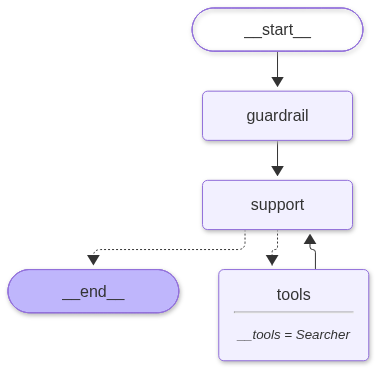

In [15]:
agent.graph